In [1]:
import ee
ee.Authenticate()
ee.Initialize(project='ndvi-project-515911')
print('Connected to Earth Engine')

Enter verification code:  4/1AUn6Hd_e8XACvcmNsyJULPXDdoE6tb5vQF258d09Zib7H5-fZnsa2Hv5qU0



Successfully saved authorization token.
Connected to Earth Engine


In [2]:
import ee
import geemap

ee.Initialize(project='ndvi-project-515911')

districts = ee.FeatureCollection('FAO/GAUL/2015/level2')
odisha = districts.filter(ee.Filter.eq('ADM1_NAME', 'Orissa'))
print(sorted(odisha.aggregate_array('ADM2_NAME').getInfo()))

C:\Users\adars\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


['Angul', 'Baleshwar', 'Baragarh', 'Bhadrak', 'Bolangir', 'Boudh', 'Cuttack', 'Deogarh', 'Dhenkanal', 'Gajapati', 'Ganjam', 'Jagatsinghpur', 'Jajpur', 'Jharsuguda', 'Kalahandi', 'Kandhamal', 'Kendrapara', 'Keonjhar', 'Khordha', 'Koraput', 'Malkangiri', 'Mayurbhanj', 'Nabarangpur', 'Nayagarh', 'Nuapada', 'Puri', 'Rayagada', 'Sambalpur', 'Sonepur', 'Sundargarh']


In [3]:
import pandas as pd

aoi = districts.filter(ee.Filter.eq('ADM1_NAME', 'Orissa')) \
               .filter(ee.Filter.eq('ADM2_NAME', 'Koraput')).geometry()

rows = []
for y in range(2001, 2026):
    s, e = f'{y}-06-01', f'{y}-11-01'
    ndvi = (ee.ImageCollection('MODIS/061/MOD13Q1').filterDate(s, e)
            .select('NDVI').mean().multiply(0.0001))
    rain = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate(s, e)
            .select('precipitation').sum())
    stats = ndvi.addBands(rain).reduceRegion(
        ee.Reducer.mean(), aoi, scale=1000, bestEffort=True).getInfo()
    rows.append({'year': y, 'ndvi': stats['NDVI'], 'rain_mm': stats['precipitation']})
    print(y, 'done')

df = pd.DataFrame(rows)
df.to_csv('ndvi_rainfall_2001_2025.csv', index=False)
df

2001 done
2002 done
2003 done
2004 done
2005 done
2006 done
2007 done
2008 done
2009 done
2010 done
2011 done
2012 done
2013 done
2014 done
2015 done
2016 done
2017 done
2018 done
2019 done
2020 done
2021 done
2022 done
2023 done
2024 done
2025 done


,year,ndvi,rain_mm
0,2001,0.396526,1404.176107
1,2002,0.513941,1133.789962
2,2003,0.433000,1569.438226
3,2004,0.511035,1499.198035
4,2005,0.467772,1698.905277
5,2006,0.483178,1684.554126
6,2007,0.519782,1654.250393
7,2008,0.479718,1463.022570
8,2009,0.509614,1232.969203
9,2010,0.533699,1666.940427


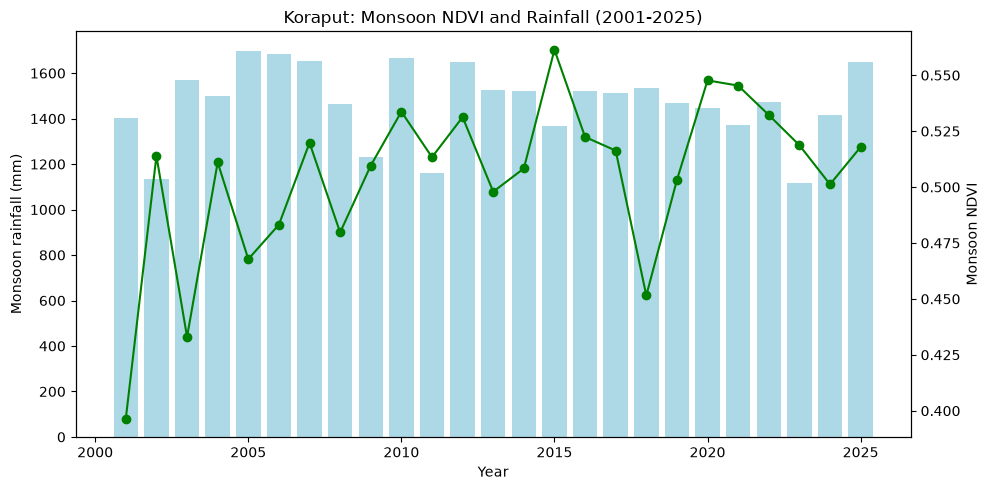

In [4]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(df['year'], df['rain_mm'], color='lightblue', label='Rainfall (mm)')
ax1.set_xlabel('Year')
ax1.set_ylabel('Monsoon rainfall (mm)')

ax2 = ax1.twinx()
ax2.plot(df['year'], df['ndvi'], color='green', marker='o', label='NDVI')
ax2.set_ylabel('Monsoon NDVI')

plt.title('Koraput: Monsoon NDVI and Rainfall (2001-2025)')
fig.tight_layout()
plt.savefig('ndvi_rainfall_plot.png', dpi=300)
plt.show()

In [5]:
import pymannkendall as mk
from scipy.stats import pearsonr

# Trend tests (slope = change per year)
for col in ['ndvi', 'rain_mm']:
    r = mk.original_test(df[col])
    print(col, '| trend:', r.trend, '| p-value:', round(r.p, 3), '| slope per year:', round(r.slope, 5))

# Correlation between NDVI and rainfall
r, p = pearsonr(df['ndvi'], df['rain_mm'])
print('Correlation r =', round(r, 2), ', p =', round(p, 3))


ndvi | trend: increasing | p-value: 0.038 | slope per year: 0.00185
rain_mm | trend: no trend | p-value: 0.252 | slope per year: -4.68102
Correlation r = -0.15 , p = 0.485


In [6]:
# Robustness check: repeat the NDVI trend test without 2001
df2 = df[df['year'] > 2001]
r2 = mk.original_test(df2['ndvi'])
print('NDVI without 2001 | trend:', r2.trend, '| p-value:', round(r2.p, 3), '| slope per year:', round(r2.slope, 5))

# Find unusual years (more than 1 standard deviation from average)
for col in ['ndvi', 'rain_mm']:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()

print(df[(df['ndvi_z'].abs() > 1) | (df['rain_mm_z'].abs() > 1)][['year', 'ndvi', 'rain_mm', 'ndvi_z', 'rain_mm_z']].round(2))


NDVI without 2001 | trend: no trend | p-value: 0.107 | slope per year: 0.00155
    year  ndvi  rain_mm  ndvi_z  rain_mm_z
0   2001  0.40  1404.18   -2.94      -0.39
1   2002  0.51  1133.79    0.25      -2.00
2   2003  0.43  1569.44   -1.95       0.59
4   2005  0.47  1698.91   -1.00       1.36
5   2006  0.48  1684.55   -0.58       1.28
6   2007  0.52  1654.25    0.41       1.10
8   2009  0.51  1232.97    0.13      -1.41
9   2010  0.53  1666.94    0.79       1.17
10  2011  0.51  1161.14    0.24      -1.84
11  2012  0.53  1649.79    0.72       1.07
14  2015  0.56  1369.56    1.54      -0.60
17  2018  0.45  1536.02   -1.44       0.39
19  2020  0.55  1446.55    1.17      -0.14
20  2021  0.55  1370.22    1.11      -0.59
22  2023  0.52  1117.90    0.38      -2.10
24  2025  0.52  1648.41    0.36       1.06


In [7]:
def masked_ndvi(y):
    s, e = f'{y}-06-01', f'{y}-11-01'
    col = (ee.ImageCollection('MODIS/061/MOD13Q1').filterDate(s, e)
           .map(lambda img: img.select('NDVI').updateMask(img.select('SummaryQA').lte(1))))
    img = col.mean().multiply(0.0001)
    return img.reduceRegion(ee.Reducer.mean(), aoi, scale=1000, bestEffort=True).getInfo()['NDVI']

df['ndvi_qa'] = [masked_ndvi(y) for y in df['year']]
df.to_csv('ndvi_rainfall_2001_2025.csv', index=False)

print(df[['year', 'ndvi', 'ndvi_qa']].round(3).head(6))

r_all = mk.original_test(df['ndvi_qa'])
print('Quality-filtered NDVI, all years | trend:', r_all.trend, '| p:', round(r_all.p, 3), '| slope:', round(r_all.slope, 5))

r_no2001 = mk.original_test(df[df['year'] > 2001]['ndvi_qa'])
print('Quality-filtered NDVI, without 2001 | trend:', r_no2001.trend, '| p:', round(r_no2001.p, 3), '| slope:', round(r_no2001.slope, 5))

   year   ndvi  ndvi_qa
0  2001  0.397    0.663
1  2002  0.514    0.599
2  2003  0.433    0.600
3  2004  0.511    0.626
4  2005  0.468    0.600
5  2006  0.483    0.651
Quality-filtered NDVI, all years | trend: increasing | p: 0.0 | slope: 0.00368
Quality-filtered NDVI, without 2001 | trend: increasing | p: 0.0 | slope: 0.00438


 year  ndvi  ndvi_qa  rain_mm
 2001 0.397    0.663 1404.176
 2002 0.514    0.599 1133.790
 2003 0.433    0.600 1569.438
 2004 0.511    0.626 1499.198
 2005 0.468    0.600 1698.905
 2006 0.483    0.651 1684.554
 2007 0.520    0.658 1654.250
 2008 0.480    0.630 1463.023
 2009 0.510    0.630 1232.969
 2010 0.534    0.680 1666.940
 2011 0.513    0.651 1161.137
 2012 0.531    0.628 1649.794
 2013 0.498    0.686 1527.289
 2014 0.508    0.672 1521.960
 2015 0.561    0.665 1369.564
 2016 0.522    0.678 1522.142
 2017 0.516    0.717 1512.816
 2018 0.452    0.657 1536.016
 2019 0.503    0.664 1470.621
 2020 0.548    0.681 1446.546
 2021 0.545    0.724 1370.217
 2022 0.532    0.651 1475.224
 2023 0.519    0.664 1117.904
 2024 0.501    0.714 1414.963
 2025 0.518    0.731 1648.413


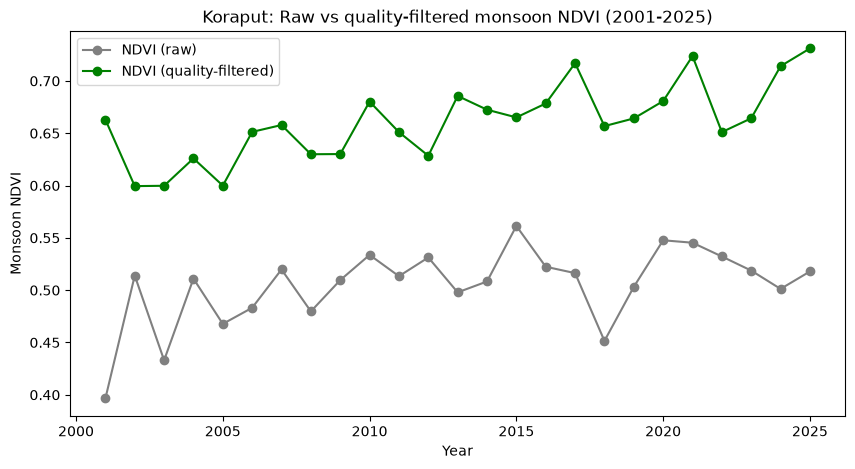

Filtered NDVI vs rainfall: r = 0.08 , p = 0.709


In [8]:
import matplotlib.pyplot as plt

print(df[['year', 'ndvi', 'ndvi_qa', 'rain_mm']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df['year'], df['ndvi'], color='grey', marker='o', label='NDVI (raw)')
ax.plot(df['year'], df['ndvi_qa'], color='green', marker='o', label='NDVI (quality-filtered)')
ax.set_xlabel('Year')
ax.set_ylabel('Monsoon NDVI')
ax.set_title('Koraput: Raw vs quality-filtered monsoon NDVI (2001-2025)')
ax.legend()
plt.savefig('ndvi_raw_vs_filtered.png', dpi=300)
plt.show()

r, p = pearsonr(df['ndvi_qa'], df['rain_mm'])
print('Filtered NDVI vs rainfall: r =', round(r, 2), ', p =', round(p, 3))

In [9]:
def yearly(y):
    y = ee.Number(y)
    col = (ee.ImageCollection('MODIS/061/MOD13Q1')
           .filterDate(ee.Date.fromYMD(y, 6, 1), ee.Date.fromYMD(y, 11, 1))
           .map(lambda img: img.select('NDVI').updateMask(img.select('SummaryQA').lte(1))))
    img = col.mean().multiply(0.0001)
    return ee.Image.constant(y).float().rename('year').addBands(img)

trend_col = ee.ImageCollection(ee.List.sequence(2001, 2025).map(yearly))
slope = trend_col.reduce(ee.Reducer.sensSlope()).select('slope').clip(aoi)

m = geemap.Map()
m.centerObject(aoi, 9)
m.addLayer(slope, {'min': -0.01, 'max': 0.01, 'palette': ['red', 'white', 'green']}, 'NDVI trend per year')
m

Map(center=[18.811116112879464, 82.7072321739708], controls=(WidgetControl(options=['position', 'transparent_b…

In [10]:
geemap.ee_export_image(
    slope,
    filename='ndvi_trend_koraput.tif',
    scale=250,
    region=aoi,
    file_per_band=False
)

Generating URL ...
Please wait ...
Data downloaded to C:\Users\adars\Desktop\ndvi-rainfall-project\ndvi_trend_koraput.tif


In [11]:
district_fc = (districts.filter(ee.Filter.eq('ADM1_NAME', 'Orissa'))
               .filter(ee.Filter.eq('ADM2_NAME', 'Koraput')))
geemap.ee_to_shp(district_fc, filename='koraput_boundary.shp')

Using format GEOPANDAS_GEODATAFRAME requires geopandas.


In [12]:
district_fc = (districts.filter(ee.Filter.eq('ADM1_NAME', 'Orissa'))
               .filter(ee.Filter.eq('ADM2_NAME', 'Koraput')))
geemap.ee_export_vector(district_fc, filename='koraput_boundary.shp')

Generating URL ...
Please wait ...
Data downloaded to C:\Users\adars\Desktop\ndvi-rainfall-project\koraput_boundary.shp
